Check-in 2: GRU baseline results, examples and failure analysis

This notebook doesn't run the model. Instead it loads the test-set predictions that `python -m src.evaluate` saved to `runs/gru_h64/test_preds.npz` (GRU, persistence and historical average, all on the same 6,832 test windows) and builds every number and figure used in [`check-in-2.md`](../check-in-2.md). Figures are saved to `figures/`, and the numbers we quote are also written to `figures/ci2_numbers.json`.

The data is read from `DATA_DIR`, which is `../Project_check_in_1/data` by default. If yours is somewhere else, pass the path to `data_paths("/path/to/data")` below.

In [1]:
import sys
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.config import data_paths, FIG_DIR, RUNS_DIR
from src.data import load_processed, load_adj, load_locations
from src.evaluate import results_table

warnings.filterwarnings("ignore", "Mean of empty slice")
RUN_NAME = "gru_h64"
paths = data_paths()
arrays, meta = load_processed(paths["processed"])
_, _, adj = load_adj(paths["adj"], sensor_ids=meta["sensor_ids"])
locations = load_locations(paths["locations"])
run = RUNS_DIR / RUN_NAME
with np.load(run / "test_preds.npz") as z:
    y = z["y"]
    preds = {"GRU": z["gru"], "Persistence": z["persistence"], "HA": z["ha"]}
    target_idx, x_missing = z["target_index"], z["x_missing_frac"]
ts = pd.DatetimeIndex(pd.to_datetime(arrays["timestamps"]))
raw, sensor_ids = arrays["raw"], np.array(meta["sensor_ids"])
s_te, e_te = meta["splits"]["test"]
obs = y != 0
err = {k: np.abs(p - y) for k, p in preds.items()}
MODELS = list(preds)
numbers = {}   # every number quoted in check-in-2.md
print(f"DATA_DIR = {paths['data_dir']}")
print(f"test windows {y.shape[0]:,} x horizons {y.shape[1]} x sensors {y.shape[2]}; observed targets {obs.mean():.1%}")

fig_dir = FIG_DIR
fig_dir.mkdir(exist_ok=True)
C1, C2, C3, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
COL = {"GRU": C1, "Persistence": C2, "HA": C3, "truth": "#222222"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
                     "lines.linewidth": 1.5})
def save(fig, name):
    fig.savefig(fig_dir / f"{name}.png")
    plt.show()

def mae(k, sel):
    # MAE of model k over the cells selected by sel (missing targets are skipped)
    sel = sel & obs
    return float(err[k][sel].mean())

DATA_DIR = /Users/mikekwon/Documents/georgetownFall26/DSAN6600/Deep-Learning-6600/Project_check_in_1/data
test windows 6,832 x horizons 12 x sensors 207; observed targets 87.9%


## 1. Training run
The config we trained with, a summary of the run, and the learning curve (all read from `runs/gru_h64/`).

,value
hidden,64
layers,2
dropout,0.1
head_hidden,128
use_mask,True
lr,0.001
weight_decay,0.0001
batch_size,64
clip,5.0
lr_factor,0.5


,value
epochs_trained,40
best_epoch,40
best_val_mae,3.249127
wall_clock_min,18.217497
n_params,51340
device,mps


mean epoch time 27.3s; final lr 2.5e-04


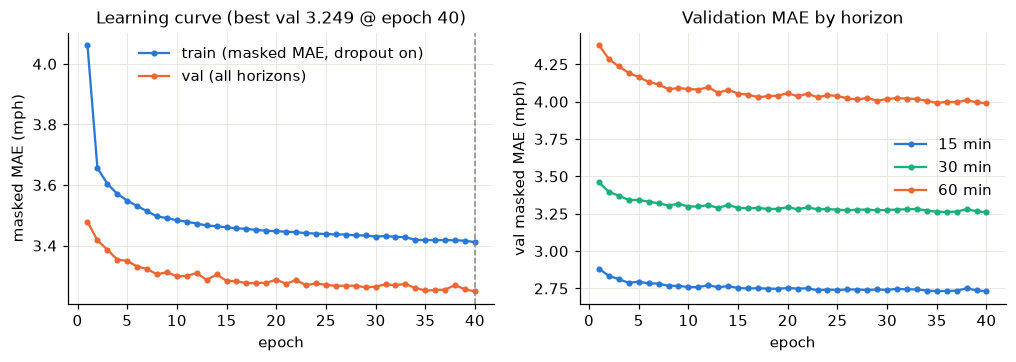

In [2]:
cfg = json.loads((run / "config.json").read_text())
summ = json.loads((run / "summary.json").read_text())
hist = pd.read_csv(run / "metrics.csv")
keys = ["hidden", "layers", "dropout", "head_hidden", "use_mask", "lr", "weight_decay", "batch_size",
        "clip", "lr_factor", "lr_patience", "es_patience", "max_epochs", "seed", "device"]
display(pd.DataFrame({"value": {k: cfg[k] for k in keys}}))
display(pd.DataFrame({"value": summ}))
numbers["training"] = {**summ, "mean_epoch_sec": float(hist.epoch_sec.mean()),
                   "lr_final": float(hist.lr.iloc[-1]), "lr_reductions": int((hist.lr.diff() < 0).sum())}
print(f"mean epoch time {hist.epoch_sec.mean():.1f}s; final lr {hist.lr.iloc[-1]:.1e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(hist.epoch, hist.train_loss, "o-", ms=3, color=C1, label="train (masked MAE, dropout on)")
ax[0].plot(hist.epoch, hist.val_mae, "o-", ms=3, color=C2, label="val (all horizons)")
ax[0].axvline(summ["best_epoch"], color=GRAY, ls="--", lw=1)
title = f"Learning curve (best val {summ['best_val_mae']:.3f} @ epoch {summ['best_epoch']})"
ax[0].set(xlabel="epoch", ylabel="masked MAE (mph)", title=title)
ax[0].legend()
for c, col, lab in [("val_mae_15", C1, "15 min"), ("val_mae_30", C3, "30 min"), ("val_mae_60", C2, "60 min")]:
    ax[1].plot(hist.epoch, hist[c], "o-", ms=3, color=col, label=lab)
ax[1].set(xlabel="epoch", ylabel="val masked MAE (mph)", title="Validation MAE by horizon")
ax[1].legend()
save(fig, "R0_learning_curve")

## 2. Test results (masked MAE / RMSE / MAPE at 15 / 30 / 60 min)
`src/evaluate.py` recomputes persistence and HA on the same test windows as the GRU, and checks that they match CI1's `figures/probe_results.csv`.

In [3]:
res = results_table({"gru": preds["GRU"], "persistence": preds["Persistence"], "ha": preds["HA"]}, y)
display(res.round(2))
saved = pd.read_csv(fig_dir / "results_table.csv", header=[0, 1], index_col=0)
assert np.allclose(saved.values.astype(float), res.round(2).values.astype(float)), "results_table.csv is stale - re-run src.evaluate"
numbers["results"] = {m: {f"{h} {k}": round(float(v), 2) for (h, k), v in r.items()} for m, r in res.iterrows()}
gru = res.iloc[0]
for h in ["15 min", "30 min", "60 min"]:
    base = res.iloc[1:3][(h, "MAE")]
    best_name, best = base.idxmin(), base.min()
    print(f"{h}: GRU MAE {gru[(h, 'MAE')]:.2f} vs best probe {best:.2f} ({best_name.split(' (')[0]}) "
          f"-> {100 * (1 - gru[(h, 'MAE')] / best):.1f}% lower")
    numbers.setdefault("gain_vs_best_probe_pct", {})[h] = round(100 * (1 - gru[(h, 'MAE')] / best), 1)

horizon                               15 min                30 min        \
metric                                   MAE  RMSE MAPE (%)    MAE  RMSE   
model                                                                      
GRU (shared-weight, ours)               2.99  5.89     8.03   3.60  7.28   
Persistence (last observed)             3.71  7.47     8.94   4.62  9.64   
Historical average (dow × tod, train)   4.19  7.86    13.06   4.19  7.86   

horizon                                        60 min                  
metric                                MAPE (%)    MAE   RMSE MAPE (%)  
model                                                                  
GRU (shared-weight, ours)                10.32   4.46   8.95    13.76  
Persistence (last observed)              11.48   6.14  12.61    15.69  
Historical average (dow × tod, train)    13.06   4.19   7.86    13.06

15 min: GRU MAE 2.99 vs best probe 3.71 (Persistence) -> 19.4% lower
30 min: GRU MAE 3.60 vs best probe 4.19 (Historical average) -> 14.2% lower
60 min: GRU MAE 4.46 vs best probe 4.19 (Historical average) -> -6.5% lower


**Takeaway.** The GRU is the best of the three models at 15 min (2.99, 19.4% below persistence) and at 30 min (3.60, 14.2% below HA). At 60 min, though, it is 6.5% worse than HA (4.46 vs 4.19), and its RMSE is higher too (8.95 vs 7.86). HA keeps a separate average for every sensor, day of week and 5-min slot. Our GRU doesn't know which sensor or which day it is looking at, so once the last hour stops being useful it has no typical profile to fall back on.

### MAE vs horizon (5–60 min)

horizon (min),5,10,15,20,25,30,35,40,45,50,55,60
GRU,2.381,2.732,2.994,3.216,3.414,3.599,3.770,3.926,4.072,4.207,4.338,4.465
Persistence,2.887,3.353,3.715,4.036,4.335,4.619,4.893,5.156,5.407,5.656,5.900,6.143
HA,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193


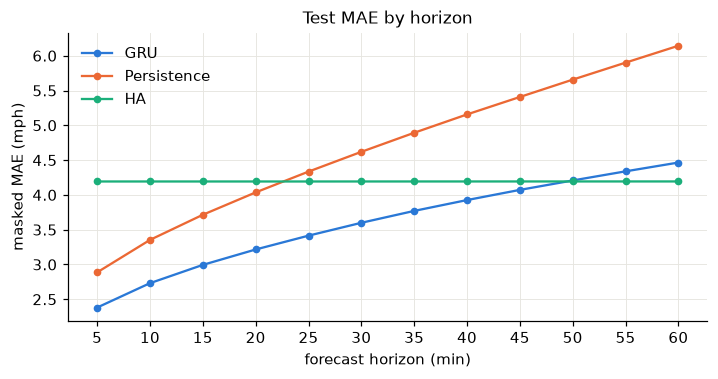

GRU beats persistence at every horizon: True; GRU < HA up to 45 min
GRU MAE grows 2.38 -> 4.46 mph from 5 to 60 min (1.87x)


In [4]:
horizons = np.arange(1, 13)
def hsel(h):
    s = np.zeros_like(obs)
    s[:, h] = True
    return s

per_h = pd.DataFrame({k: [mae(k, hsel(h)) for h in range(12)] for k in MODELS}, index=horizons * 5)
per_h.index.name = "horizon (min)"
display(per_h.round(3).T)
per_h.round(3).to_csv(fig_dir / "mae_by_horizon.csv")
cross = per_h.index[(per_h.GRU < per_h.HA)].max()
numbers["mae_by_horizon"] = per_h.round(2).to_dict()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for k in MODELS:
    ax.plot(per_h.index, per_h[k], "o-", ms=4, color=COL[k], label=k)
ax.set(xlabel="forecast horizon (min)", ylabel="masked MAE (mph)", title="Test MAE by horizon", xticks=range(5, 65, 5))
ax.legend()
save(fig, "R1_mae_by_horizon")
print(f"GRU beats persistence at every horizon: {(per_h.GRU < per_h.Persistence).all()}; "
      f"GRU < HA up to {cross} min" if (per_h.GRU < per_h.HA).any() else "GRU never beats HA")
print(f"GRU MAE grows {per_h.GRU.iloc[0]:.2f} -> {per_h.GRU.iloc[-1]:.2f} mph from 5 to 60 min "
      f"({per_h.GRU.iloc[-1] / per_h.GRU.iloc[0]:.2f}x)")

**Takeaway.** The GRU beats persistence at every horizon. Its error grows from 2.38 to 4.46 mph between 5 and 60 min (1.87 times), while persistence's grows 2.13 times. The GRU overtakes HA's error somewhere between 45 min (4.07, still below 4.19) and 50 min (4.21).

### Congested (target < 40 mph) vs free-flow (≥ 40 mph)

,horizon,regime,share of targets,GRU,Persistence,HA
0,15 min,congested (<40),0.124,7.448,7.341,12.899
1,15 min,free-flow (>=40),0.876,2.366,3.203,2.964
2,30 min,congested (<40),0.124,10.182,9.674,12.900
3,30 min,free-flow (>=40),0.876,2.670,3.905,2.964
4,60 min,congested (<40),0.124,14.456,13.418,12.905
5,60 min,free-flow (>=40),0.876,3.056,5.117,2.965


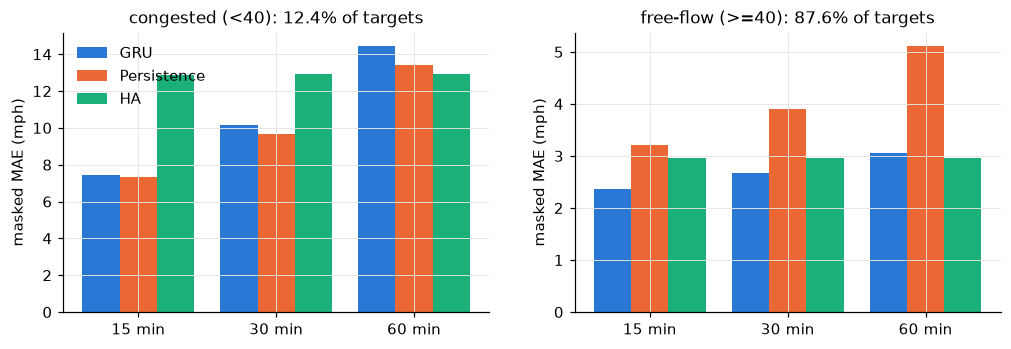

60 min: GRU congested MAE 14.46 vs free-flow 3.06 (4.7x); congested targets are 12.4% of the test set


In [5]:
congested, free_flow = obs & (y < 40), obs & (y >= 40)
rows = []
for h in (3, 6, 12):
    for regime, R in [("congested (<40)", congested), ("free-flow (>=40)", free_flow)]:
        sel = np.zeros_like(obs)
        sel[:, h - 1] = True
        sel &= R
        rows.append({"horizon": f"{h * 5} min", "regime": regime, "share of targets": sel.sum() / (obs[:, h - 1].sum()),
                     **{k: mae(k, sel) for k in MODELS}})
reg = pd.DataFrame(rows)
display(reg.round(3))
reg.round(3).to_csv(fig_dir / "mae_congested_vs_free.csv", index=False)
numbers["regime"] = reg.round(2).to_dict("records")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.3), sharey=False)
for ax, regime in zip(axs, reg.regime.unique()):
    d = reg[reg.regime == regime].set_index("horizon")[MODELS]
    xs = np.arange(len(d))
    for i, k in enumerate(MODELS):
        ax.bar(xs + (i - 1) * 0.27, d[k], 0.27, color=COL[k], label=k)
    ax.set(xticks=xs, xticklabels=d.index, ylabel="masked MAE (mph)",
           title=f"{regime}: {reg[reg.regime == regime]['share of targets'].iloc[0]:.1%} of targets")
axs[0].legend()
save(fig, "R2_congested_vs_free")
c60 = reg[(reg.horizon == "60 min")].set_index("regime")
print(f"60 min: GRU congested MAE {c60.loc['congested (<40)', 'GRU']:.2f} vs free-flow {c60.loc['free-flow (>=40)', 'GRU']:.2f} "
      f"({c60.loc['congested (<40)', 'GRU'] / c60.loc['free-flow (>=40)', 'GRU']:.1f}x); "
      f"congested targets are {c60.loc['congested (<40)', 'share of targets']:.1%} of the test set")

**Takeaway.** Only 12.4% of test targets are congested, but at 60 min the GRU's MAE on them is 14.46 mph, compared with 3.06 in free flow (4.7 times higher). In congestion the GRU is actually worse than plain persistence at every horizon (7.45 vs 7.34 at 15 min, 10.18 vs 9.67 at 30, 14.46 vs 13.42 at 60), and worse than HA at 60 min (12.91). Its advantage comes from free flow, where it beats both baselines at 15 and 30 min. Even there, HA is slightly better at 60 min (2.97 vs 3.06).

## 3. Qualitative examples
Rather than hand-picking examples, we let the code choose them, using only full weekdays in the test set (days where every 5-min slot has a 60-min-ahead prediction):
* **(a) The GRU does well:** among sensor-days with real congestion (some reading below 40 mph, at least 95% observed), the one with the lowest GRU 60-min MAE.
* **(b) Sudden congestion:** the biggest 30-min drop in observed speed, on a sensor-day that is at least 90% observed.
* **(c) Right after a network outage:** the longest outage of all sensors that ends on a full test weekday. We show the sensor with the largest GRU 15-min error in the hour after the data comes back.

Each panel compares the true speed with the GRU and HA forecasts at 15 min (h = 3) and 60 min (h = 12). Every prediction is drawn at the time it is predicting, not the time it was made.

17 full test weekdays: 2012-06-05 .. 2012-06-27


network-wide outages in test: 22 runs, 666 steps total


,start,end,steps
15,2012-06-17 21:15:00,2012-06-18 11:00:00,166
13,2012-06-16 21:30:00,2012-06-17 11:15:00,166
8,2012-06-09 04:05:00,2012-06-09 13:50:00,118
11,2012-06-16 02:10:00,2012-06-16 08:00:00,71
14,2012-06-17 15:55:00,2012-06-17 19:30:00,44


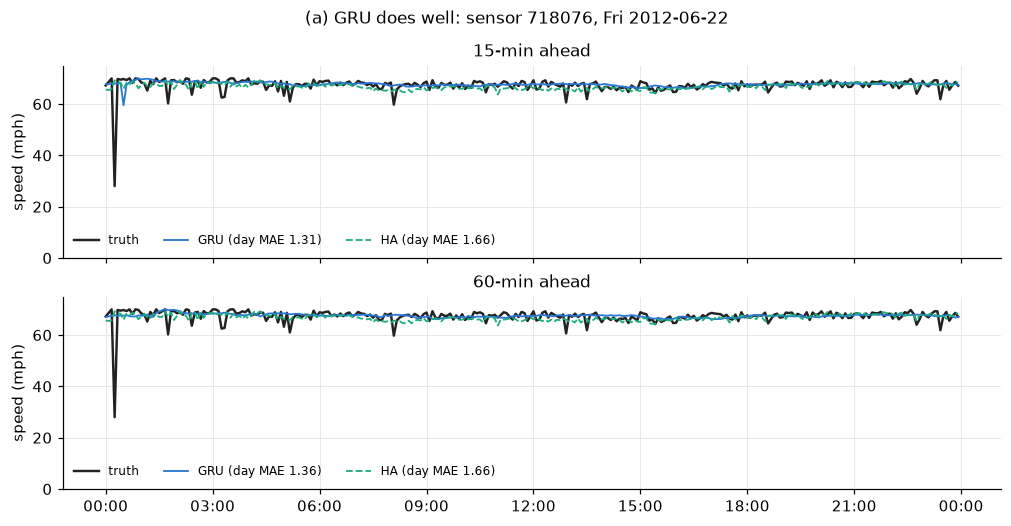

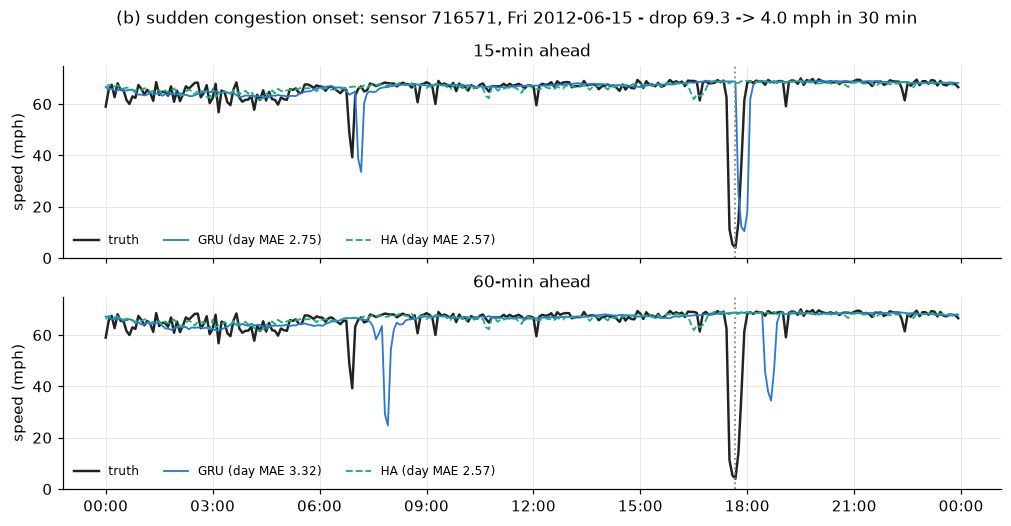

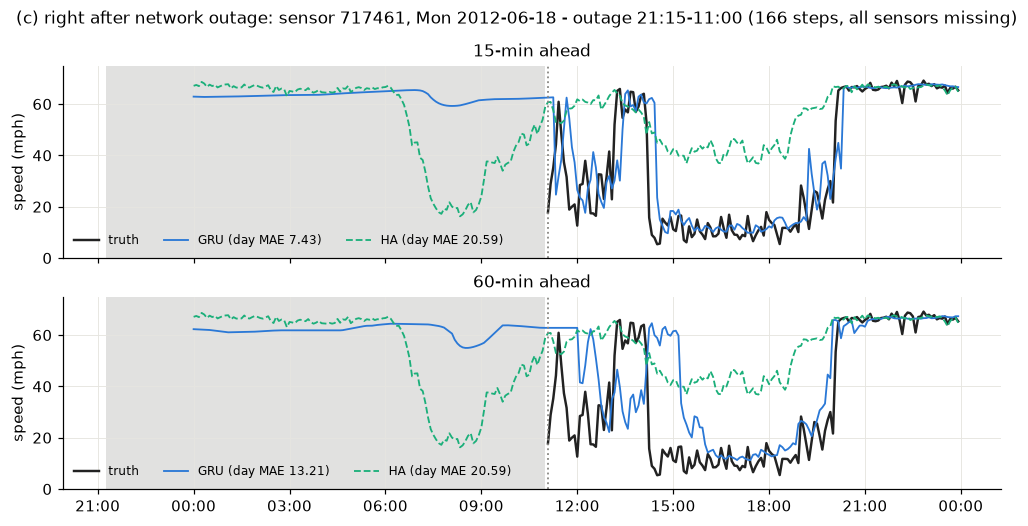

,case,sensor_id,date,event_time,note,GRU MAE 15min,HA MAE 15min,GRU MAE 60min,HA MAE 60min
0,(a) GRU does well,718076,2012-06-22 (Fri),,,1.31,1.66,1.36,1.66
1,(b) sudden congestion onset,716571,2012-06-15 (Fri),2012-06-15 17:40,drop 69.3 -> 4.0 mph in 30 min,2.75,2.57,3.32,2.57
2,(c) right after network outage,717461,2012-06-18 (Mon),2012-06-18 11:05,"outage 21:15-11:00 (166 steps, all sensors mis...",7.43,20.59,13.21,20.59


In [6]:
n_times = len(ts)
def series(k, h):
    out = np.full((n_times, y.shape[2]), np.nan, np.float32)
    out[target_idx[:, h - 1]] = preds[k][:, h - 1]
    return out
pred_series = {(k, h): series(k, h) for k in MODELS for h in (3, 12)}
truth = np.where(raw > 0, raw, np.nan).astype(np.float32)
ts_day = ts.normalize()
covered = ~np.isnan(pred_series[("GRU", 12)][:, 0])
days = [d for d in ts_day[s_te:e_te].unique() if d.dayofweek < 5 and covered[ts_day == d].all() and (ts_day == d).sum() == 288]
print(f"{len(days)} full test weekdays: {days[0].date()} .. {days[-1].date()}")

def day_idx(d):
    return np.where(ts_day == d)[0]

# (a) lowest GRU-60 day MAE among congested, well-observed sensor-days
best = (np.inf, None, None)
for d in days:
    ix = day_idx(d)
    tr, pr = truth[ix], pred_series[("GRU", 12)][ix]
    ok = (np.isfinite(tr).mean(0) >= 0.95) & (np.nanmin(np.where(np.isfinite(tr), tr, 99), 0) < 40)
    m = np.nanmean(np.abs(pr - tr), 0)
    m[~ok] = np.inf
    n = int(np.argmin(m))
    if m[n] < best[0]:
        best = (float(m[n]), d, n)
case_a = {"case": "(a) GRU does well", "sensor_idx": best[2], "day": best[1], "t": None}

# (b) largest 30-min drop on a full weekday
drop = np.full_like(truth, np.nan)
drop[6:] = truth[:-6] - truth[6:]  # speed drop over the last 30 min
valid = np.zeros(n_times, bool)
valid[np.concatenate([day_idx(d) for d in days])] = True
dd = np.where(valid[:, None], drop, np.nan)
# go through drops from biggest to smallest, stop at the first well-observed sensor-day
order = np.argsort(np.nan_to_num(dd, nan=-1), axis=None)[::-1]
for t, n in zip(*np.unravel_index(order, dd.shape)):
    if np.isfinite(truth[day_idx(ts_day[t]), n]).mean() >= 0.9:
        break
case_b = {"case": "(b) sudden congestion onset", "sensor_idx": int(n), "day": ts_day[t], "t": int(t),
          "note": f"drop {truth[t - 6, n]:.1f} -> {truth[t, n]:.1f} mph in 30 min"}

# (c) longest network-wide outage ending on a full test weekday
allzero = (raw == 0).all(1)
runs, t0 = [], None
for t in range(s_te, e_te):
    if allzero[t] and t0 is None:
        t0 = t
    if not allzero[t] and t0 is not None:
        runs.append((t0, t - 1))
        t0 = None
out_runs = pd.DataFrame([{"start": ts[a], "end": ts[b], "steps": b - a + 1, "a": a, "b": b} for a, b in runs])
print(f"network-wide outages in test: {len(out_runs)} runs, {out_runs.steps.sum()} steps total")
display(out_runs.sort_values("steps", ascending=False).head(5)[["start", "end", "steps"]])
cand = out_runs[out_runs.end.dt.normalize().isin(days)].sort_values("steps", ascending=False)
oa, ob = int(cand.iloc[0].a), int(cand.iloc[0].b)
after = np.arange(ob + 1, ob + 13)
e15 = np.abs(pred_series[("GRU", 3)][after] - truth[after])
e15[:, np.isfinite(truth[after]).sum(0) < 10] = np.nan
n_c = int(np.nanargmax(np.nanmean(e15, 0)))
case_c = {"case": "(c) right after network outage", "sensor_idx": n_c, "day": ts_day[ob], "t": ob + 1,
          "note": f"outage {ts[oa]:%H:%M}-{ts[ob]:%H:%M} ({ob - oa + 1} steps, all sensors missing)"}
numbers["outages_test"] = {"runs": len(out_runs), "steps": int(out_runs.steps.sum())}

def plot_case(c, fname):
    ix, n = day_idx(c["day"]), c["sensor_idx"]
    t_ax = ts[ix]
    fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    row = {"case": c["case"], "sensor_id": sensor_ids[n], "date": f"{c['day']:%Y-%m-%d (%a)}",
           "event_time": "" if c["t"] is None else f"{ts[c['t']]:%Y-%m-%d %H:%M}", "note": c.get("note", "")}
    for ax, h in zip(axs, (3, 12)):
        tr = truth[ix, n]
        ax.plot(t_ax, tr, color=COL["truth"], lw=1.6, label="truth")
        for k, ls in [("GRU", "-"), ("HA", "--")]:
            pr = pred_series[(k, h)][ix, n]
            e = float(np.nanmean(np.abs(pr - tr)))
            row[f"{k} MAE {h * 5}min"] = round(e, 2)
            ax.plot(t_ax, pr, ls, color=COL[k], lw=1.2, label=f"{k} (day MAE {e:.2f})")
        if c["t"] is not None:
            ax.axvline(ts[c["t"]], color=GRAY, ls=":", lw=1.2)
        if c["case"].startswith("(c)"):
            ax.axvspan(ts[oa], ts[ob], color=GRAY, alpha=0.25, lw=0)
        ax.set(ylabel="speed (mph)", title=f"{h * 5}-min ahead", ylim=(0, 75))
        ax.legend(loc="lower left", fontsize=8, ncol=3)
    axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    title = f"{c['case']}: sensor {sensor_ids[n]}, {c['day']:%a %Y-%m-%d}"
    if c.get("note"):
        title += f" - {c['note']}"
    fig.suptitle(title, fontsize=11)
    save(fig, fname)
    return row

cases = pd.DataFrame([plot_case(case_a, "Q1_good_sensor"), plot_case(case_b, "Q2_congestion_onset"),
                      plot_case(case_c, "Q3_after_outage")])
cases.to_csv(fig_dir / "qualitative_cases.csv", index=False)
numbers["qualitative"] = cases.to_dict("records")
display(cases)

**Takeaways.**
* **(a)** Sensor 718076 (Fri 2012-06-22): the GRU follows a congested day closely. Its day MAE is 1.31 / 1.36 mph at 15 / 60 min, compared with 1.66 for HA.
* **(b)** Sensor 716571 (Fri 2012-06-15, falling from 69.3 to 4.0 mph by 17:40): the GRU does predict the crash, but one horizon late. It is 15 min late at h = 3 and about an hour late at h = 12, when the real congestion has already cleared. Its day MAE (2.75 / 3.32) ends up worse than HA's (2.57), even though HA just predicts free flow.
* **(c)** Sensor 717461 (Mon 2012-06-18), right after a 166-step outage of the whole network that ends at 11:00. The first predictions after the outage are made from inputs that are all missing, so they sit near free-flow speed. Once real data comes back, the GRU picks up the day's unusual all-afternoon congestion (day MAE 7.43 / 13.21). HA can't see what is happening today and scores 20.59.

## 4. Failure analysis
### 4.1 MAE by time of day, weekday vs weekend

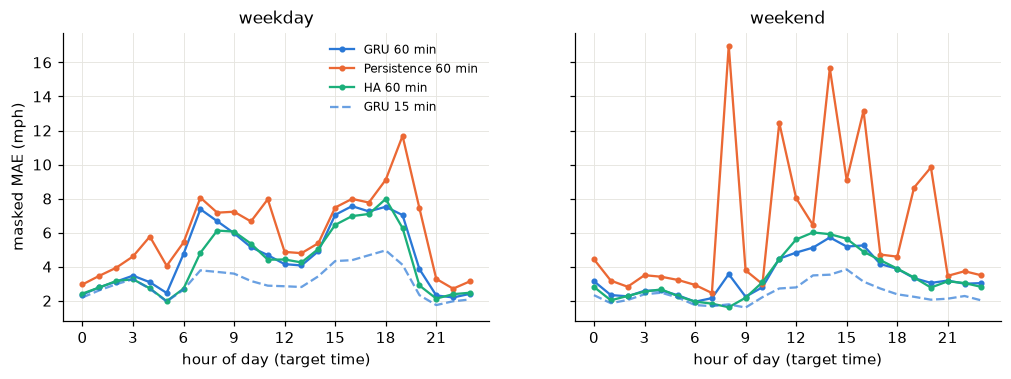

GRU 60-min weekday: peak 7.56 mph at 16:00, night (0-4h) 2.97
AM 7-9h 6.67, PM 15-18h 7.34
weekend peak 5.72 at 14:00, weekend mean 3.42 vs weekday mean 4.67
weekday hours where GRU-60 is worse than HA: [1, 3, 4, 5, 6, 7, 8, 11, 15, 16, 17, 19, 20, 21]


In [7]:
hour = ts.hour.to_numpy()[target_idx]                    # (W, 12) hour of the target time
wkend = (ts.dayofweek.to_numpy() >= 5)[target_idx]
rows = []
for h in (3, 12):
    o = obs[:, h - 1]
    for k in MODELS:
        e = np.where(o, err[k][:, h - 1], 0).sum(1)
        c = o.sum(1)
        g = pd.DataFrame({"hour": hour[:, h - 1], "weekend": wkend[:, h - 1], "e": e, "c": c}).groupby(["weekend", "hour"]).sum()
        for (we, hr), r in g.iterrows():
            rows.append({"horizon": h * 5, "model": k, "weekend": we, "hour": hr, "MAE": r.e / r.c})
tod = pd.DataFrame(rows)
tod.to_csv(fig_dir / "mae_by_tod.csv", index=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, we in zip(axs, (False, True)):
    for k in MODELS:
        d = tod[(tod.horizon == 60) & (tod.model == k) & (tod.weekend == we)]
        ax.plot(d.hour, d.MAE, "o-", ms=3, color=COL[k], label=f"{k} 60 min")
    d = tod[(tod.horizon == 15) & (tod.model == "GRU") & (tod.weekend == we)]
    ax.plot(d.hour, d.MAE, "--", color=C1, alpha=0.7, label="GRU 15 min")
    ax.set(xlabel="hour of day (target time)", title="weekend" if we else "weekday", xticks=range(0, 24, 3))
axs[0].set_ylabel("masked MAE (mph)")
axs[0].legend(fontsize=8)
save(fig, "FA1_mae_by_tod")
g = tod[(tod.model == "GRU") & (tod.horizon == 60)]
wd, we_ = g[~g.weekend].set_index("hour").MAE, g[g.weekend].set_index("hour").MAE
night = wd.loc[0:4].mean()
am = wd.loc[7:9].mean()
pm = wd.loc[15:18].mean()
numbers["tod"] = {
    "wd_peak_hour": int(wd.idxmax()),
    "wd_peak_mae": round(wd.max(), 2),
    "wd_night_mae_0_4": round(night, 2),
    "wd_am_7_9": round(am, 2),
    "wd_pm_15_18": round(pm, 2),
    "we_peak_hour": int(we_.idxmax()),
    "we_peak_mae": round(we_.max(), 2),
    "we_mean": round(we_.mean(), 2),
    "wd_mean": round(wd.mean(), 2),
}
print(f"GRU 60-min weekday: peak {wd.max():.2f} mph at {wd.idxmax()}:00, night (0-4h) {night:.2f}")
print(f"AM 7-9h {am:.2f}, PM 15-18h {pm:.2f}")
print(f"weekend peak {we_.max():.2f} at {we_.idxmax()}:00, weekend mean {we_.mean():.2f} vs weekday mean {wd.mean():.2f}")
ha_wd = tod[(tod.model == "HA") & (tod.horizon == 60) & (~tod.weekend)].set_index("hour").MAE
worse_than_ha = wd[wd > ha_wd].index.tolist()
numbers["tod"]["gru60_worse_than_ha_hours_weekday"] = worse_than_ha
print(f"weekday hours where GRU-60 is worse than HA: {worse_than_ha}")

**Takeaway.** On weekdays the GRU's 60-min error peaks at 7.56 mph at 16:00, compared with 2.97 overnight (0–4 h). It averages 6.67 in the morning rush (7–9 h) and 7.34 in the evening rush (15–18 h). Weekends are lower and flatter (mean 3.42 vs 4.67 on weekdays). The 60-min GRU is worse than HA in 14 of the 24 weekday hours, including the hours when rush hour begins (7–8 and 15–17 h). So it loses exactly where the daily congestion starts, which HA effectively knows from the calendar. The big persistence spikes on weekends come from long weekend outages, where an all-missing input makes persistence predict 0.

### 4.2 Lag around sharp drops
**What counts as an event:** the observed speed falls by more than 15 mph within 30 min (6 steps), ending at time *t₀*, with both ends observed. We keep at most one event per sensor per hour.

*A caveat:* because we pick events by a high value at t₀ − 30 min and a low value at t₀, the averaged truth shows a spike at −30 min and a dip at 0 that partly come from the selection itself (regression to the mean). The predictions copy that spike, shifted by their horizon.

**How we measure lag:** first we define the midpoint of the drop, *m* = (mean truth over [t₀−60, t₀−35 min] + min truth over [t₀, t₀+60 min]) / 2. The lag is the number of 5-min steps between the truth first falling below *m* and the prediction first falling below it, searching from t₀−30 min to t₀+2 h. If the prediction never gets below *m* in that range, we count it as "never".

9,974 sharp-drop events at 207 sensors


,model,horizon (min),events,never crosses,median lag (steps),IQR,"MAE in [t0, t0+60]"
0,GRU,15,9974,0.25,3.0,3–4,9.57
1,GRU,60,9974,0.40,12.0,9–13,15.99
2,Persistence,15,9974,0.02,3.0,3–3,10.00
3,Persistence,60,9974,0.02,12.0,0–12,16.77
4,HA,any,9974,0.57,2.0,-2–9,11.73


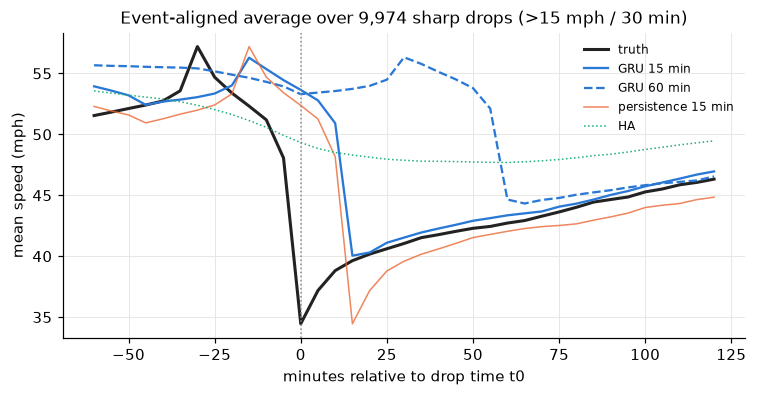

GRU-15 median lag 3 steps (15 min), GRU-60 median lag 12 steps (60 min); GRU-60 never reaches the midpoint in 40% of events


In [8]:
offsets = np.arange(-12, 25)
cand = (drop > 15) & np.isfinite(drop)
lo, hi = s_te + 23 + 12, e_te - 25            # every offset has a 60-min-ahead prediction
ev = []
for n in range(y.shape[2]):
    last = -10**9
    for t in np.where(cand[lo:hi, n])[0] + lo:
        if t - last >= 12:
            ev.append((t, n))
            last = t
ev = np.array(ev)
print(f"{len(ev):,} sharp-drop events at {len(np.unique(ev[:, 1]))} sensors")
tt = ev[:, :1] + offsets[None]                                # (E, len(offsets))
aligned = {"truth": truth[tt, ev[:, 1:2]]}
for k in MODELS:
    for h in (3, 12):
        aligned[(k, h)] = pred_series[(k, h)][tt, ev[:, 1:2]]
pre = np.nanmean(aligned["truth"][:, (offsets >= -12) & (offsets <= -7)], 1)
post = np.nanmin(aligned["truth"][:, (offsets >= 0) & (offsets <= 12)], 1)
mid = (pre + post) / 2
search = offsets >= -6
def first_cross(a):
    below = (a < mid[:, None]) & search[None]
    return np.where(below.any(1), offsets[np.argmax(below, 1)], np.nan)
c_true = first_cross(aligned["truth"])
lag_rows = []
lags = {}
for k, h in [("GRU", 3), ("GRU", 12), ("Persistence", 3), ("Persistence", 12), ("HA", 3)]:
    lag = first_cross(aligned[(k, h)]) - c_true
    lags[(k, h)] = lag
    ok = np.isfinite(lag)
    after_t0 = (offsets >= 0) & (offsets <= 12)
    mae_after = float(np.nanmean(np.abs(aligned[(k, h)] - aligned["truth"])[:, after_t0]))
    lag_rows.append({
        "model": k,
        "horizon (min)": h * 5 if k != "HA" else "any",
        "events": len(lag),
        "never crosses": 1 - ok.mean(),
        "median lag (steps)": np.median(lag[ok]),
        "IQR": f"{np.percentile(lag[ok], 25):.0f}–{np.percentile(lag[ok], 75):.0f}",
        "MAE in [t0, t0+60]": mae_after,
    })
lagtab = pd.DataFrame(lag_rows)
display(lagtab.round(2))
lagtab.round(2).to_csv(fig_dir / "drop_lag.csv", index=False)
numbers["drop_lag"] = {
    "events": int(len(ev)),
    "sensors": int(len(np.unique(ev[:, 1]))),
    "table": lagtab.round(2).to_dict("records"),
}

fig, ax = plt.subplots(figsize=(8, 3.6))
xm = offsets * 5
ax.plot(xm, np.nanmean(aligned["truth"], 0), color=COL["truth"], lw=2, label="truth")
ax.plot(xm, np.nanmean(aligned[("GRU", 3)], 0), color=C1, label="GRU 15 min")
ax.plot(xm, np.nanmean(aligned[("GRU", 12)], 0), color=C1, ls="--", label="GRU 60 min")
ax.plot(xm, np.nanmean(aligned[("Persistence", 3)], 0), color=C2, lw=1, alpha=0.8, label="persistence 15 min")
ax.plot(xm, np.nanmean(aligned[("HA", 3)], 0), color=C3, lw=1, ls=":", label="HA")
ax.axvline(0, color=GRAY, ls=":", lw=1)
ax.set(xlabel="minutes relative to drop time t0", ylabel="mean speed (mph)",
       title=f"Event-aligned average over {len(ev):,} sharp drops (>15 mph / 30 min)")
ax.legend(fontsize=8)
save(fig, "FA2_drop_lag")
g15, g60 = lags[("GRU", 3)], lags[("GRU", 12)]
print(f"GRU-15 median lag {np.nanmedian(g15):.0f} steps ({5 * np.nanmedian(g15):.0f} min), GRU-60 median lag "
      f"{np.nanmedian(g60):.0f} steps ({5 * np.nanmedian(g60):.0f} min); GRU-60 never reaches the midpoint in "
      f"{np.isnan(g60).mean():.0%} of events")

**Takeaway.** Across 9,974 sharp drops, the GRU's median lag is the same as its horizon: 3 steps at 15 min (IQR 3–4) and 12 steps at 60 min (IQR 9–13), exactly matching persistence (3 and 12). In 40% of events the 60-min prediction never even reaches the midpoint of the drop. In other words, the model reacts once the drop shows up in its own inputs, rather than seeing it coming. In the hour after t₀ its 60-min MAE is 15.99 mph, close to persistence (16.77) and worse than HA (11.73).

### 4.3 MAE vs missing values in the input window
Here we group targets by how many of the sensor's own 12 input steps were missing. (The mask channel tells the GRU which steps were filled in with the train mean.)

,missing input steps,horizon (min),share of targets,GRU,Persistence,HA
0,0,15,0.943,2.944,3.455,4.154
1,0,60,0.926,4.376,5.313,4.153
2,1–3,15,0.028,3.288,3.804,4.679
3,1–3,60,0.031,4.418,5.278,4.461
4,4–6,15,0.011,3.573,3.929,5.542
5,4–6,60,0.014,5.561,6.323,5.416
6,7–11,15,0.013,3.793,4.195,4.658
7,7–11,60,0.015,5.302,6.210,4.812
8,12 (all),15,0.004,8.287,59.135,4.563
9,12 (all),60,0.015,8.275,59.537,4.382


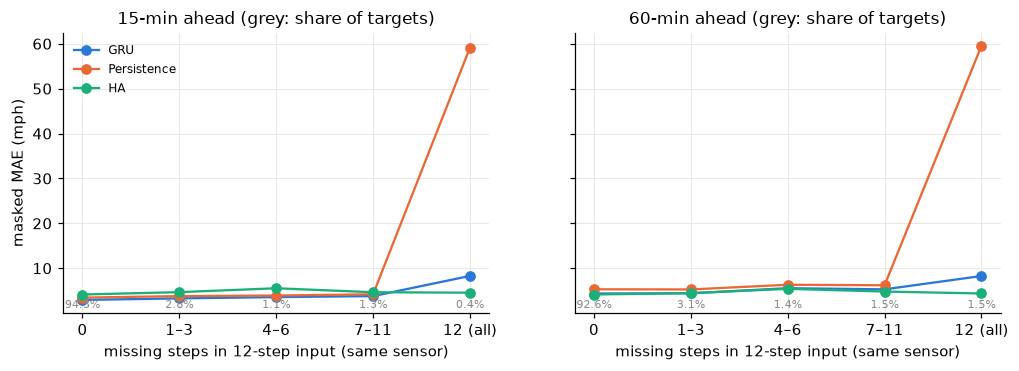

GRU-15 MAE: 0 missing 2.94 -> all missing 8.29 mph (HA 4.56)
GRU-60 MAE: 0 missing 4.38 -> all missing 8.27 mph (HA 4.38)


In [9]:
kmiss = np.rint(x_missing * 12).astype(int)                     # (W, N) missing input steps
bins = [(0, 0, "0"), (1, 3, "1–3"), (4, 6, "4–6"), (7, 11, "7–11"), (12, 12, "12 (all)")]
rows = []
for lo_, hi_, lab in bins:
    b = (kmiss >= lo_) & (kmiss <= hi_)
    for h in (3, 12):
        sel = np.zeros_like(obs)
        sel[:, h - 1] = b
        sel &= obs
        rows.append({"missing input steps": lab, "horizon (min)": h * 5, "share of targets": sel.sum() / obs[:, h - 1].sum(),
                     **{k: mae(k, sel) for k in MODELS}})
miss = pd.DataFrame(rows)
display(miss.round(3))
miss.round(3).to_csv(fig_dir / "mae_vs_missing.csv", index=False)
numbers["missing"] = miss.round(2).to_dict("records")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
for ax, h in zip(axs, (15, 60)):
    d = miss[miss["horizon (min)"] == h].set_index("missing input steps")
    for k in MODELS:
        ax.plot(d.index, d[k], "o-", color=COL[k], label=k)
    for i, (lab, r) in enumerate(d.iterrows()):
        ax.annotate(f"{r['share of targets']:.1%}", (i, ax.get_ylim()[0]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7, color=GRAY)
    ax.set(xlabel="missing steps in 12-step input (same sensor)", title=f"{h}-min ahead (grey: share of targets)")
axs[0].set_ylabel("masked MAE (mph)")
axs[0].legend(fontsize=8)
save(fig, "FA3_mae_vs_missing")
m60 = miss[miss["horizon (min)"] == 60].set_index("missing input steps")
m15 = miss[miss["horizon (min)"] == 15].set_index("missing input steps")
for name, m in [("GRU-15", m15), ("GRU-60", m60)]:
    print(f"{name} MAE: 0 missing {m.loc['0', 'GRU']:.2f} -> all missing {m.loc['12 (all)', 'GRU']:.2f} mph "
          f"(HA {m.loc['12 (all)', 'HA']:.2f})")

**Takeaway.** 94.3% of 15-min targets have a complete input window, and there the GRU's MAE is 2.94. A few missing steps don't cost much (3.29–3.79 at 15 min). But when all 12 input steps are missing (0.4% / 1.5% of 15 / 60-min targets), the GRU's error jumps to 8.29 / 8.27 mph, against 4.56 / 4.38 for HA. Mean-filling plus the mask lets the model know that the data is missing, but it still has nothing to base a forecast on.

### 4.4 Per-sensor MAE and the spatial signal
First we compute each sensor's masked MAE over all test windows. Then, for the 10 worst sensors (by GRU 60-min MAE), we check whether their neighbours in the road graph slowed down first:
* A **large-error event** is the start of a stretch where the GRU's 60-min prediction is at least 15 mph too high (i.e. it missed congestion). We keep at most one per hour.
* For each event, the sensor's own **drop time** τᵢ is the first step in [t₀ − 2 h, t₀ + 30 min] where its speed fell by more than 10 mph within 30 min. Events without such a drop are skipped.
* Another sensor j "dropped earlier" if it had the same kind of drop (more than 10 mph within 30 min) ending in the 30 min before τᵢ, i.e. in [τᵢ − 30 min, τᵢ).
* We split neighbours by the direction of the DCRNN edges (`adj[i, j]` is the edge i→j): **into i** means adj[j, i] > 0.1, and **out of i** means adj[i, j] > 0.1.
* **Control:** sensors that aren't neighbours (all of them, plus a random set of the same size, seed 6600). During rush hour lots of sensors slow down around the same time, so a neighbour is only informative if it drops first more often than an arbitrary sensor does.

,sensor_id,GRU 60,GRU 15,HA,Persistence 60,test missing rate,mean speed,share <40 mph,in-degree,out-degree
rank,,,,,,,,,,
1,717462,10.08,5.09,11.75,11.16,0.10,47.500000,0.40,14,13
2,718045,9.91,5.77,7.52,11.19,0.14,48.330002,0.30,6,14
3,717461,9.81,4.94,10.01,10.53,0.20,43.360001,0.48,17,11
4,717458,9.68,4.96,9.04,10.03,0.10,40.630001,0.50,13,15
5,773939,9.53,5.39,9.91,11.47,0.10,50.810001,0.25,3,3
6,717466,9.15,5.11,11.95,10.90,0.10,49.959999,0.32,14,11
7,717468,9.14,4.72,12.76,10.69,0.10,48.869999,0.28,14,14
8,716339,9.02,4.05,7.13,8.78,0.10,37.450001,0.56,15,13
9,717472,8.65,4.45,12.36,10.53,0.13,53.720001,0.25,10,12


Spearman corr of per-sensor GRU-60 MAE with: {'share <40 mph': 0.89, 'test missing rate': 0.13, 'mean speed': -0.81}
worst 10 sensors (4.8% of sensors) carry 10.1% of GRU-60 absolute error


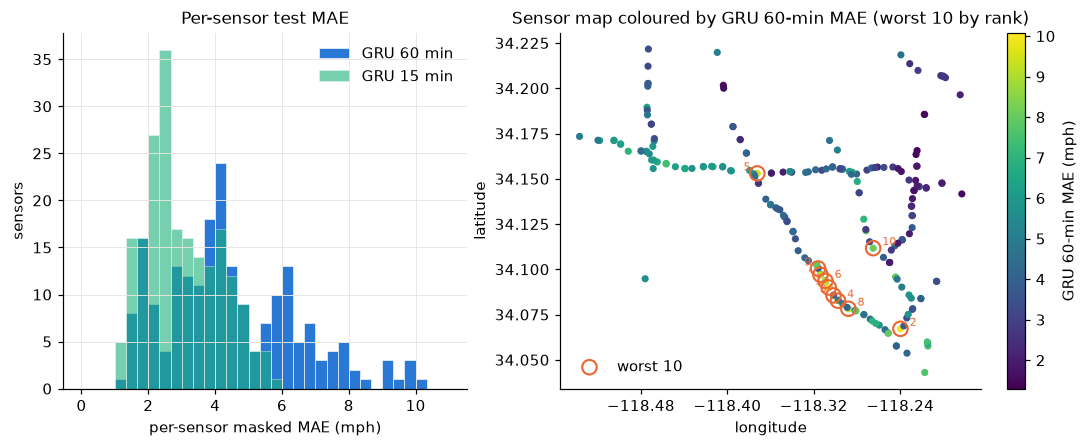

In [10]:
smae = {k: {h: np.where(obs[:, h - 1], err[k][:, h - 1], 0).sum(0) / obs[:, h - 1].sum(0) for h in (3, 12)} for k in MODELS}
miss_rate = (raw[s_te:e_te] == 0).mean(0)
mean_spd = np.nanmean(truth[s_te:e_te], 0)
cong_share = np.nanmean(np.where(np.isfinite(truth[s_te:e_te]), truth[s_te:e_te] < 40, np.nan), 0)
sens = pd.DataFrame({"sensor_id": sensor_ids, "GRU 60": smae["GRU"][12], "GRU 15": smae["GRU"][3], "HA": smae["HA"][12],
                     "Persistence 60": smae["Persistence"][12], "test missing rate": miss_rate,
                     "mean speed": mean_spd, "share <40 mph": cong_share,
                     "in-degree": (adj > 0.1).sum(0) - 1, "out-degree": (adj > 0.1).sum(1) - 1})
sens.round(3).to_csv(fig_dir / "per_sensor_mae.csv", index=False)
worst = sens.sort_values("GRU 60", ascending=False).head(10)
display(worst.round(2).assign(rank=range(1, 11)).set_index("rank"))
rho = sens[["GRU 60", "share <40 mph", "test missing rate", "mean speed"]].corr(method="spearman")["GRU 60"]
print("Spearman corr of per-sensor GRU-60 MAE with:", rho.drop("GRU 60").round(2).to_dict())
tot_err = np.where(obs[:, 11], err["GRU"][:, 11], 0).sum(0)
gru60_mae = sens["GRU 60"]
numbers["per_sensor"] = {
    "median": round(float(np.median(gru60_mae)), 2),
    "p90": round(float(np.percentile(gru60_mae, 90)), 2),
    "max": round(float(gru60_mae.max()), 2),
    "min": round(float(gru60_mae.min()), 2),
    "worst10": worst[["sensor_id", "GRU 60", "HA", "share <40 mph", "test missing rate"]].round(2).to_dict("records"),
    "spearman": rho.drop("GRU 60").round(2).to_dict(),
    "worst10_share_of_total_abs_err": round(float(tot_err[worst.index].sum() / tot_err.sum()), 3),
}
print(f"worst 10 sensors ({10 / len(sensor_ids):.1%} of sensors) carry {tot_err[worst.index].sum() / tot_err.sum():.1%} of GRU-60 absolute error")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
hb = np.linspace(0, np.ceil(sens["GRU 60"].max()), 34)
axs[0].hist(sens["GRU 60"], bins=hb, color=C1, edgecolor="white", linewidth=0.4, label="GRU 60 min")
axs[0].hist(sens["GRU 15"], bins=hb, color=C3, alpha=0.6, edgecolor="white", linewidth=0.4, label="GRU 15 min")
axs[0].set(xlabel="per-sensor masked MAE (mph)", ylabel="sensors", title="Per-sensor test MAE")
axs[0].legend()
loc = locations.reindex(sensor_ids)
sc = axs[1].scatter(loc.longitude, loc.latitude, c=sens["GRU 60"], cmap="viridis", s=22, edgecolor="none")
w = loc.loc[worst.sensor_id]
axs[1].scatter(w.longitude, w.latitude, s=90, facecolor="none", edgecolor=C2, lw=1.4, label="worst 10")
for rank, (sid, r) in enumerate(w.iterrows(), 1):
    axs[1].annotate(str(rank), (r.longitude, r.latitude), xytext=(-9 if rank % 2 else 6, 2), textcoords="offset points", fontsize=7, color=C2)
axs[1].xaxis.set_major_locator(plt.MaxNLocator(5))
plt.colorbar(sc, ax=axs[1], label="GRU 60-min MAE (mph)")
axs[1].set(xlabel="longitude", ylabel="latitude", title="Sensor map coloured by GRU 60-min MAE (worst 10 by rank)")
axs[1].legend(loc="lower left")
axs[1].grid(False)
save(fig, "FA4_sensor_mae")

,events,into: share earlier,out: share earlier,non-nbr: share earlier,any nbr earlier,any random (matched) earlier
sensor_id,,,,,,
717462,95,0.08,0.31,0.14,0.93,0.84
718045,85,0.12,0.17,0.12,0.87,0.72
717461,97,0.11,0.30,0.12,0.90,0.84
717458,106,0.10,0.27,0.11,0.94,0.83
773939,90,0.17,0.30,0.16,0.78,0.54
717466,106,0.10,0.32,0.16,0.96,0.90
717468,83,0.09,0.31,0.15,0.98,0.88
716339,68,0.13,0.27,0.10,0.94,0.79
717472,76,0.10,0.36,0.16,0.95,0.91


892 large-error drop events at the worst 10 sensors
dropped in the 30 min before the target:
  into-i neighbours   12% (0.8x non-neighbours)
  out-of-i neighbours 27% (1.9x non-neighbours)
  non-neighbours      14%
at least one neighbour dropped first in 89% of events, vs 81% for a random set of the same size


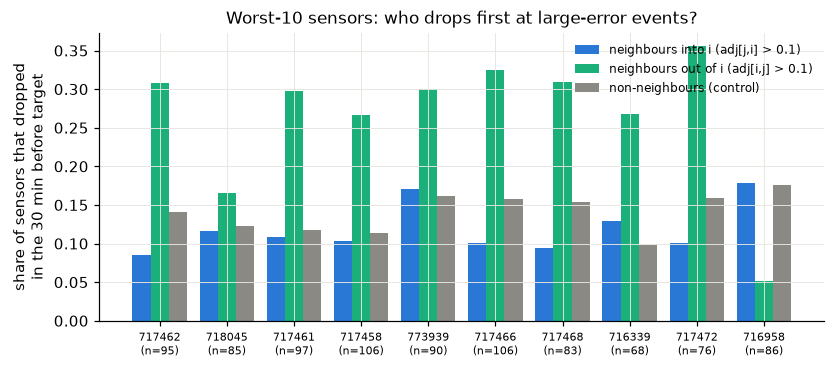

In [11]:
d10 = np.full_like(truth, np.nan)
d10[6:] = truth[:-6] - truth[6:]
drop10 = np.nan_to_num(d10, nan=0) > 10
rng = np.random.default_rng(6600)
gru60 = pred_series[("GRU", 12)]
nb_rows = []
for i in worst.index:
    over = (gru60[:, i] - truth[:, i]) > 15
    over[:s_te + 23] = False
    events, last = [], -10**9
    for t in np.where(over)[0]:
        if t - last >= 12 and not over[t - 1]:
            events.append(t)
            last = t
    into = [j for j in np.where(adj[:, i] > 0.1)[0] if j != i]
    outo = [j for j in np.where(adj[i, :] > 0.1)[0] if j != i]
    nbrs = set(into) | set(outo)
    pool = np.array([j for j in range(len(sensor_ids)) if j not in nbrs and j != i])
    for t0 in events:
        own = np.where(drop10[max(t0 - 24, 0):t0 + 7, i])[0]
        if len(own) == 0:
            continue
        tau = max(t0 - 24, 0) + own[0]
        early = drop10[tau - 6:tau].any(0)                     # (N,) dropped in the 30 min before tau
        ctrl = rng.choice(pool, size=min(len(nbrs), len(pool)), replace=False)
        nb_rows.append({"sensor_id": sensor_ids[i], "t0": ts[t0], "tau": ts[tau], "n_into": len(into), "n_out": len(outo),
                        "into: share earlier": early[into].mean() if into else np.nan,
                        "out: share earlier": early[outo].mean() if outo else np.nan,
                        "non-nbr: share earlier": early[pool].mean(),
                        "any nbr earlier": early[list(nbrs)].any() if nbrs else np.nan,
                        "any random (matched) earlier": early[ctrl].any()})
nb = pd.DataFrame(nb_rows)
nb.to_csv(fig_dir / "worst_sensor_neighbor_events.csv", index=False)
cols = ["into: share earlier", "out: share earlier", "non-nbr: share earlier", "any nbr earlier", "any random (matched) earlier"]
nb[cols] = nb[cols].astype(float)
summary_nb = nb.groupby("sensor_id")[cols].mean()
summary_nb.insert(0, "events", nb.groupby("sensor_id").size())
summary_nb = summary_nb.reindex(worst.sensor_id).dropna(how="all")
display(summary_nb.round(2))
tot = nb[cols].mean()
ratio_in = tot["into: share earlier"] / tot["non-nbr: share earlier"]
ratio_out = tot["out: share earlier"] / tot["non-nbr: share earlier"]
print(f"{len(nb)} large-error drop events at the worst {nb.sensor_id.nunique()} sensors")
print("dropped in the 30 min before the target:")
print(f"  into-i neighbours   {tot['into: share earlier']:.0%} ({ratio_in:.1f}x non-neighbours)")
print(f"  out-of-i neighbours {tot['out: share earlier']:.0%} ({ratio_out:.1f}x non-neighbours)")
print(f"  non-neighbours      {tot['non-nbr: share earlier']:.0%}")
print(f"at least one neighbour dropped first in {tot['any nbr earlier']:.0%} of events, "
      f"vs {tot['any random (matched) earlier']:.0%} for a random set of the same size")
numbers["neighbors"] = {"events": int(len(nb)), "sensors": int(nb.sensor_id.nunique())}
for k, v in tot.items():
    numbers["neighbors"][k] = round(float(v), 3)
numbers["neighbors"]["ratio_into_vs_nonnbr"] = round(float(ratio_in), 2)
numbers["neighbors"]["ratio_out_vs_nonnbr"] = round(float(ratio_out), 2)

fig, ax = plt.subplots(figsize=(8.5, 3.4))
xs = np.arange(len(summary_nb))
for o, (c, col, lab) in enumerate([("into: share earlier", C1, "neighbours into i (adj[j,i] > 0.1)"),
                                   ("out: share earlier", C3, "neighbours out of i (adj[i,j] > 0.1)"),
                                   ("non-nbr: share earlier", GRAY, "non-neighbours (control)")]):
    ax.bar(xs + (o - 1) * 0.27, summary_nb[c], 0.27, color=col, label=lab)
ax.set(xticks=xs, xticklabels=[f"{s}\n(n={int(e)})" for s, e in zip(summary_nb.index, summary_nb.events)],
       ylabel="share of sensors that dropped\nin the 30 min before target", title="Worst-10 sensors: who drops first at large-error events?")
ax.tick_params(axis="x", labelsize=7)
ax.legend(fontsize=8)
save(fig, "FA4b_neighbor_lead")

**Takeaway.** The GRU's 60-min MAE ranges from 1.30 to 10.08 mph across sensors (median 4.21, 90th percentile 7.03). What drives it is mostly how often a sensor is congested (Spearman ρ = 0.89 with the share of readings under 40 mph, and −0.81 with mean speed), not missing data (ρ = 0.13). The errors are also clustered in space: seven of the worst 10 sensors sit next to each other on one corridor (717458–717472 and 716339; ranks 1, 3, 4 and 6–9 on the map).

**Spatial evidence.** Across the worst sensors' 892 large-error events, 27% of out-of-i neighbours (adj[i, j] > 0.1) had already slowed down in the 30 min before the target did, compared with 14% of non-neighbours (1.9 times as often). In-neighbours were no more useful than random sensors (12%, 0.8 times). If the DCRNN edges point in the direction of traffic, "out of i" means downstream, which fits congestion spreading backwards from a bottleneck. Either way, the early warning sits at specific neighbours in the graph, and a GRU that looks at one sensor at a time never sees it.

### 4.5 From failure patterns to CI3
| # | Failure pattern (evidence) | What we will do in CI3 |
|---|---|---|
| 1 | **Lag = horizon at congestion onset**: median lag 3 / 12 steps at 15 / 60 min, the same as persistence (§4.2, Q2). | Graph WaveNet with forward + backward diffusion over `adj_METR-LA.pkl`. Downstream neighbours drop first 1.9× more often than random (§4.4). |
| 2 | **Worse than persistence in congestion** at every horizon (14.46 vs 13.42 mph at 60 min, §2). | Report congested-regime MAE as a headline CI3 metric for graph vs no-graph. |
| 3 | **Worse than HA at 60 min** (4.46 vs 4.19), because it has no sensor or calendar context. | Give both CI3 models the same day-of-week input. Graph WaveNet's adaptive adjacency (learned node embeddings) adds sensor identity; the no-graph model gets the same embeddings, so the ablation tests only the graph. |
| 4 | **All-missing inputs** (8.27 vs HA 4.38 at 60 min, §4.3). | Spatial models can borrow observed neighbours. Re-run the §4.3 breakdown for the graph model. |
| 5 | **Errors cluster on one congested corridor** (worst 10 carry 10.1% of absolute error; ρ = 0.89 with congestion share). | Per-sensor MAE map for graph vs no-graph: gains should concentrate on this corridor if the graph helps. |

**CI3 plan:** we will train Graph WaveNet on exactly this pipeline (same `DATA_DIR`, split, normalization, mask channel, masked-MAE loss and early stopping on val). To check that the graph is what helps, we will compare it against the same model with no graph (real plus adaptive adjacency vs identity adjacency, same training budget). If Graph WaveNet isn't stable in time, we will fall back to DCRNN.

## 5. Optional extras: seed variance and mask-channel ablation
These extra runs use the same config as the main run. We either changed only the seed (0, 1 and 2, alongside the main run's 42) or removed the mask channel (`--no-mask`, seed 42). Each one was scored on the same test windows by `src.evaluate` (saved in `runs/<run>/test_metrics.json`). If those runs aren't there, this cell just skips them.

In [12]:
HORIZONS = ["15 min", "30 min", "60 min"]

def load_run(name):
    r = RUNS_DIR / name
    if not (r / "test_metrics.json").exists():
        return None
    m = json.loads((r / "test_metrics.json").read_text())
    sm = json.loads((r / "summary.json").read_text())
    row = {"run": name}
    for h in HORIZONS:
        row[f"{h} MAE"] = m[h]["MAE"]
    for h in HORIZONS:
        row[f"{h} RMSE"] = m[h]["RMSE"]
    row["best val MAE"] = sm["best_val_mae"]
    row["epochs"] = sm["epochs_trained"]
    row["best epoch"] = sm["best_epoch"]
    row["min"] = sm["wall_clock_min"]
    return row

seed_runs = []
for name in ["gru_h64", "gru_h64_seed0", "gru_h64_seed1", "gru_h64_seed2"]:
    r = load_run(name)
    if r:
        seed_runs.append(r)
nomask = load_run("gru_h64_nomask")
if len(seed_runs) > 1:
    sr = pd.DataFrame(seed_runs).set_index("run")
    display(sr.round(3))
    agg = sr.agg(["mean", "std"]).round(3)
    display(agg)
    numbers["seeds"] = {
        "n": len(sr),
        "runs": sr.round(3).reset_index().to_dict("records"),
        "mean": agg.loc["mean"].to_dict(),
        "std": agg.loc["std"].to_dict(),
    }
    print(f"GRU test MAE over {len(sr)} seeds (mean ± std):")
    for h in HORIZONS:
        print(f"  {h}: {agg.loc['mean', f'{h} MAE']:.2f} ± {agg.loc['std', f'{h} MAE']:.2f}")
if nomask:
    nm = pd.DataFrame([seed_runs[0], nomask]).set_index("run")
    display(nm.round(3))
    numbers["mask_ablation"] = nm.round(3).reset_index().to_dict("records")
    print("no-mask minus mask (seed 42), test MAE:")
    for h in HORIZONS:
        print(f"  {h}: {nomask[f'{h} MAE'] - seed_runs[0][f'{h} MAE']:+.3f}")
    # all-missing breakdown needs predictions; only summary metrics are stored for the extra runs

,15 min MAE,30 min MAE,60 min MAE,15 min RMSE,30 min RMSE,60 min RMSE,best val MAE,epochs,best epoch,min
run,,,,,,,,,,
gru_h64,2.994,3.599,4.465,5.892,7.276,8.948,3.249,40,40,18.217
gru_h64_seed0,2.996,3.603,4.471,5.903,7.292,8.962,3.254,40,40,19.642
gru_h64_seed1,2.996,3.605,4.484,5.897,7.272,8.943,3.258,40,39,18.468
gru_h64_seed2,3.000,3.608,4.472,5.903,7.282,8.936,3.255,40,40,18.012


,15 min MAE,30 min MAE,60 min MAE,15 min RMSE,30 min RMSE,60 min RMSE,best val MAE,epochs,best epoch,min
mean,2.996,3.604,4.473,5.899,7.280,8.947,3.254,40.0,39.75,18.585
std,0.002,0.003,0.008,0.005,0.009,0.011,0.004,0.0,0.50,0.729


GRU test MAE over 4 seeds (mean ± std):
  15 min: 3.00 ± 0.00
  30 min: 3.60 ± 0.00
  60 min: 4.47 ± 0.01


,15 min MAE,30 min MAE,60 min MAE,15 min RMSE,30 min RMSE,60 min RMSE,best val MAE,epochs,best epoch,min
run,,,,,,,,,,
gru_h64,2.994,3.599,4.465,5.892,7.276,8.948,3.249,40,40,18.217
gru_h64_nomask,3.016,3.629,4.498,5.975,7.360,9.018,3.266,40,40,18.235


no-mask minus mask (seed 42), test MAE:
  15 min: +0.021
  30 min: +0.030
  60 min: +0.033


In [13]:
(fig_dir / "ci2_numbers.json").write_text(json.dumps(numbers, indent=1, default=str))
print("wrote", fig_dir / "ci2_numbers.json")

wrote /Users/mikekwon/Documents/georgetownFall26/DSAN6600/Deep-Learning-6600/Project_check_in_2/figures/ci2_numbers.json
